# Julián Álvarez — perfil de jugador, Mundial 2022

Análisis con **StatsBomb Open Data** (datos de evento + *360 freeze frames*) sobre los 7 partidos de Argentina en Qatar 2022.

**Data: StatsBomb** — [github.com/hudl/open-data](https://github.com/hudl/open-data), usada bajo la StatsBomb Public Data User Agreement.

La pregunta no es "dónde toca la pelota" (eso ya lo sabés): es **qué pasa alrededor de sus tiros y sus acciones** — y para eso están los frames 360: la posición de todos los jugadores visibles en cada evento.

In [1]:
# Dependencias — correr una vez (si ya están instaladas, pip verifica y sigue)
%pip install -q pandas matplotlib mplsoccer

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: C:\Users\k3vca\Desktop\Proyectos\fuchibol\.venv\Scripts\python.exe -m pip install --upgrade pip


## 1. Cargar los datos

Correr esta notebook **desde la raíz del repo** (los JSON ya están en `data/`).

In [2]:
%matplotlib inline
import json
from pathlib import Path

import pandas as pd
from matplotlib.figure import Figure
from mplsoccer import Pitch

ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
JULIAN = 29560  # Julián Álvarez en StatsBomb
MATCHES = {
    3857300: ("vs Saudi Arabia", "Group"),
    3857289: ("vs Mexico", "Group"),
    3857264: ("vs Poland", "Group"),
    3869151: ("vs Australia", "R16"),
    3869321: ("vs Netherlands", "QF"),
    3869519: ("vs Croatia", "SF"),
    3869685: ("vs France", "Final"),
}
ORDER = [3857300, 3857289, 3857264, 3869151, 3869321, 3869519, 3869685]

def load():
    events, frames = [], {}
    for mid in ORDER:
        evs = json.loads((ROOT / "data" / "events" / f"{mid}.json").read_text(encoding="utf-8"))
        for ev in evs:
            ev["match_id"] = mid
        events += evs
        for fr in json.loads((ROOT / "data" / "three_sixty" / f"{mid}.json").read_text(encoding="utf-8")):
            frames[fr["event_uuid"]] = fr
    return events, frames

def juvian(events):
    return [e for e in events if (e.get("player") or {}).get("id") == JULIAN]

events, frames = load()
print(f"{len(events)} eventos cargados · {len(frames)} frames 360 · {len(juvian(events))} de Julián")

27827 eventos cargados · 23386 frames 360 · 658 de Julián


## 2. Los tiros: volumen y calidad

Cada tiro trae su `statsbomb_xg` (probabilidad de gol esperada). Sumamos por partido y comparamos con los goles reales.

In [3]:
def shot_rows(events, frames):
    rows = []
    for e in juvian(events):
        if e["type"]["name"] != "Shot":
            continue
        shot = e["shot"]
        fr = frames.get(e["id"])
        nearest = None
        if fr:
            loc = e["location"]
            rivals = [p for p in fr["freeze_frame"] if not p["teammate"] and not p["keeper"] and p.get("location")]
            if rivals:
                nearest = min(((loc[0] - p["location"][0]) ** 2 + (loc[1] - p["location"][1]) ** 2) ** 0.5
                              for p in rivals)
        rows.append({
            "match": e["match_id"], "minute": e["minute"], "x": e["location"][0], "y": e["location"][1],
            "xg": shot["statsbomb_xg"], "outcome": shot["outcome"]["name"],
            "goal": shot["outcome"]["name"] == "Goal",
            "defender_m": nearest,
        })
    return pd.DataFrame(rows)

shots = shot_rows(events, frames)
print(f"tiros: {len(shots)} | goles: {int(shots.goal.sum())} | xG total: {shots.xg.sum():.2f} | xG/tiro: {shots.xg.mean():.3f}")
print(f"sobre-rendimiento: {int(shots.goal.sum()) - shots.xg.sum():+.2f}")
shots

tiros: 11 | goles: 4 | xG total: 1.91 | xG/tiro: 0.173
sobre-rendimiento: +2.09


,match,minute,x,y,xg,outcome,goal,defender_m
0,3857300,100,112.5,33.2,0.061390,Saved,False,2.806532
1,3857264,27,110.8,47.7,0.149358,Blocked,False,2.600558
2,3857264,35,110.4,27.6,0.190838,Saved,False,3.458359
3,3857264,42,102.4,27.0,0.037203,Saved,False,1.533003
4,3857264,55,107.7,41.5,0.152008,Blocked,False,3.102884
5,3857264,66,106.0,33.5,0.100542,Goal,True,1.386908
6,3857264,72,106.1,52.6,0.181460,Off T,False,1.004255
7,3869151,56,110.4,50.3,0.280607,Goal,True,2.554434
8,3869519,38,112.7,37.4,0.361724,Goal,True,NaN
9,3869519,68,113.3,45.4,0.333664,Goal,True,NaN


### Mapa de tiros

Tamaño = xG del tiro · verde = gol · naranja = atajado · gris = otro.

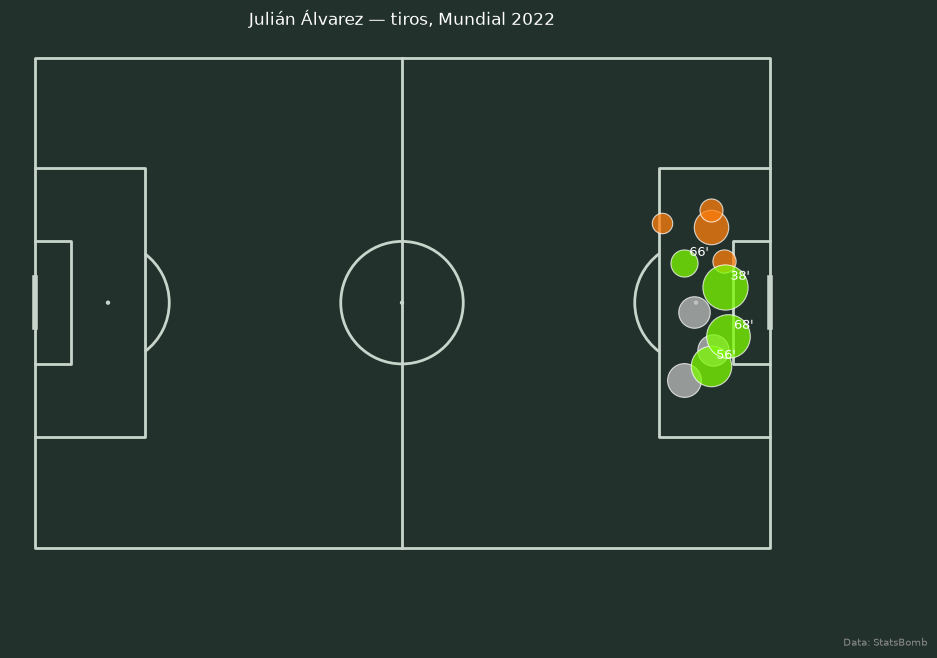

In [4]:
def shot_map(shots):
    pitch = Pitch(pitch_type="statsbomb", pitch_color="#22312b", line_color="#c7d5cc")
    fig = Figure(figsize=(11, 7))
    ax = fig.add_subplot()
    pitch.draw(ax=ax)
    for _, r in shots.iterrows():
        color = "#7CFC00" if r.goal else "#ff7f0e" if r.outcome in ("Saved", "Saved To Post") else "#bdbdbd"
        ax.scatter(r.x, r.y, s=120 + 2600 * r.xg, color=color, alpha=0.75,
                   edgecolors="white", linewidths=0.8, zorder=3)
        if r.goal:
            ax.annotate(f"{r.minute}'", (r.x, r.y), fontsize=9, color="white",
                        xytext=(4, 5), textcoords="offset points", zorder=4)
    ax.set_title("Julián Álvarez — tiros, Mundial 2022", color="white", fontsize=12)
    fig.text(0.99, 0.005, "Data: StatsBomb", ha="right", fontsize=7, color="0.55")
    fig.patch.set_facecolor("#22312b")
    return fig

display(shot_map(shots))

### xG vs goles por partido

La barra es lo esperado; el punto rojo, lo que metió.

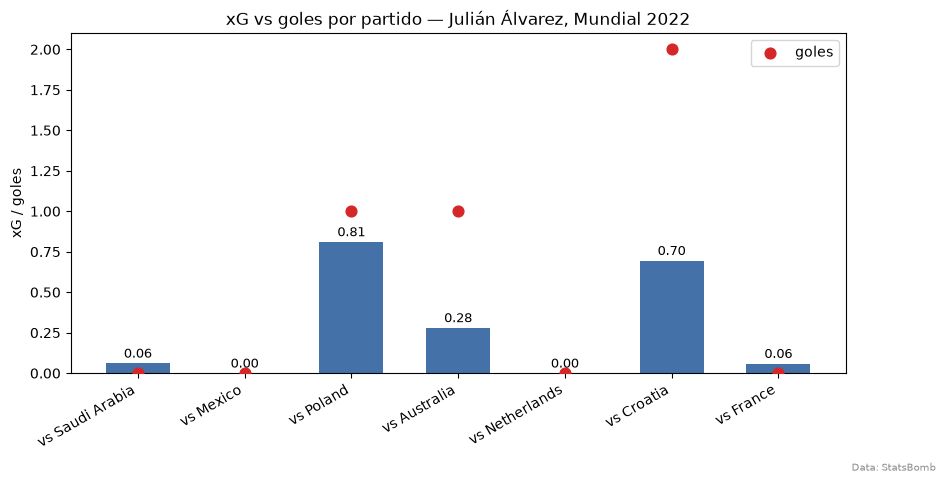

In [5]:
def xg_by_match(shots):
    fig = Figure(figsize=(10, 5))
    ax = fig.add_subplot()
    g = shots.groupby("match").agg(xg=("xg", "sum"), goals=("goal", "sum")).reindex(ORDER).fillna(0)
    labels = [MATCHES[m][0] for m in ORDER]
    ax.bar(labels, g.xg, color="#4472a8", width=0.6)
    ax.scatter(labels, g.goals, color="#d62728", zorder=3, s=60, label="goles")
    for i, xg in enumerate(g.xg):
        ax.annotate(f"{xg:.2f}", (i, xg), textcoords="offset points", xytext=(0, 4), ha="center", fontsize=9)
    ax.set_ylabel("xG / goles")
    ax.set_title("xG vs goles por partido — Julián Álvarez, Mundial 2022")
    ax.legend()
    fig.autofmt_xdate()
    fig.text(0.99, 0.005, "Data: StatsBomb", ha="right", fontsize=7, color="0.55")
    return fig

display(xg_by_match(shots))

## 3. El diferencial 360: ¿con cuánta presión tira?

El xG tradicional sabe dónde estaba el balón. El **freeze frame** sabe dónde estaba **todo el mundo**. Para cada tiro con frame disponible medimos la distancia al defensor rival más cercano en ese instante.

Hipótesis: sus goles no salen de chances limpias — salen con marca encima.

presión media al tirar: 2.28 m (mediana 2.55)
tiros con defensor a menos de 2 m: 3 de 9


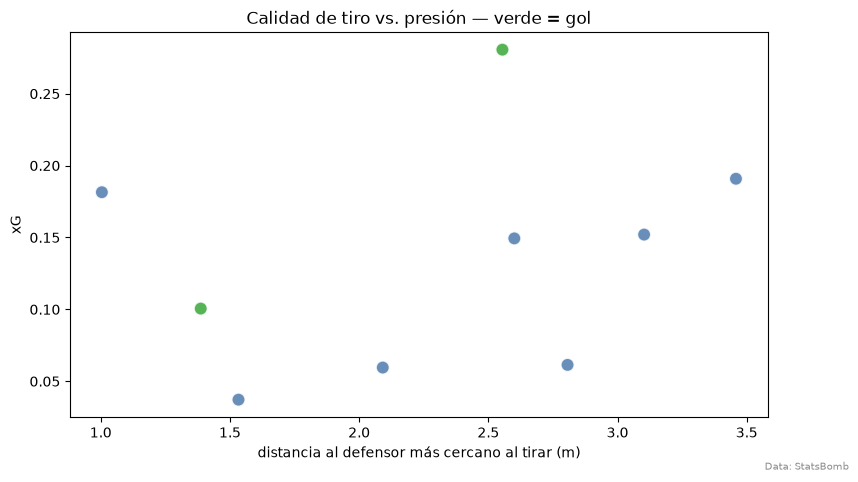

In [6]:
def shot_pressure(shots):
    fig = Figure(figsize=(9, 5))
    ax = fig.add_subplot()
    s = shots.dropna(subset=["defender_m"])
    colors = s.goal.map({True: "#2ca02c", False: "#4472a8"})
    ax.scatter(s.defender_m, s.xg, c=colors, s=90, alpha=0.8, edgecolors="white")
    ax.set_xlabel("distancia al defensor más cercano al tirar (m)")
    ax.set_ylabel("xG")
    ax.set_title("Calidad de tiro vs. presión — verde = gol")
    fig.text(0.99, 0.005, "Data: StatsBomb", ha="right", fontsize=7, color="0.55")
    return fig

s = shots.dropna(subset=["defender_m"])
print(f"presión media al tirar: {s.defender_m.mean():.2f} m (mediana {s.defender_m.median():.2f})")
print(f"tiros con defensor a menos de 2 m: {(s.defender_m < 2).sum()} de {len(s)}")
display(shot_pressure(shots))

## 4. El trabajo sin pelota

El 9 de Scaloni también era el primer defensor. Los eventos `Pressure` de Julián, en el mapa.

recepciones: 193 (22 bajo presión, 11%) · presiones: 118 · asistencias de tiro: 2


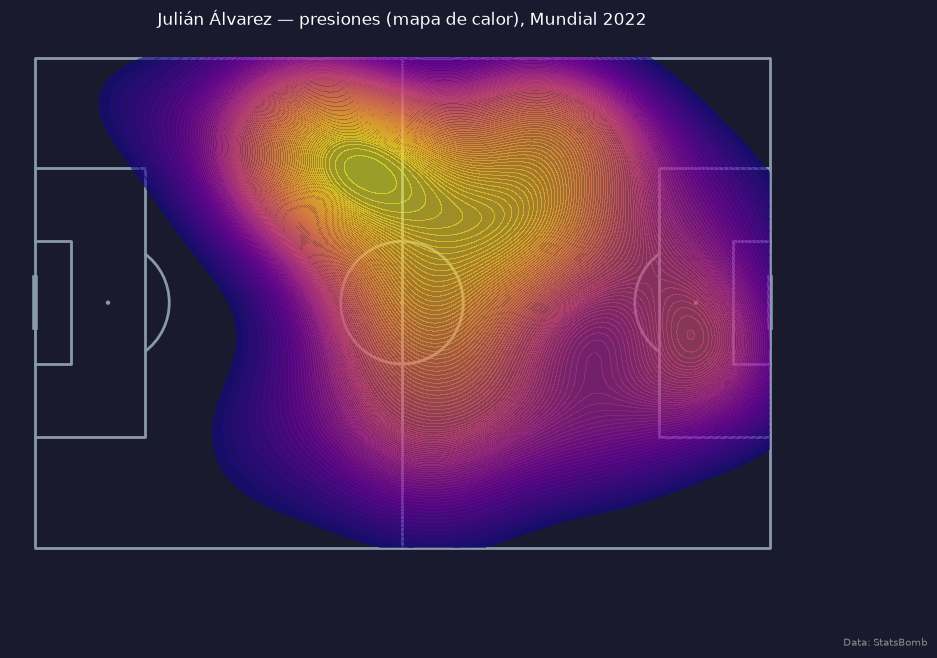

In [7]:
receipts = [e for e in juvian(events) if e["type"]["name"] == "Ball Receipt*"]
under = sum(1 for e in receipts if e.get("under_pressure"))
press_locs = [(e["location"][0], e["location"][1]) for e in juvian(events)
              if e["type"]["name"] == "Pressure" and e.get("location")]
assists = sum(1 for e in juvian(events) if e["type"]["name"] == "Pass"
              and e.get("pass", {}).get("shot_assist"))
print(f"recepciones: {len(receipts)} ({under} bajo presión, {100*under/len(receipts):.0f}%) · presiones: {len(press_locs)} · asistencias de tiro: {assists}")

pitch = Pitch(pitch_type="statsbomb", pitch_color="#1a1a2e", line_color="#8899aa")
fig = Figure(figsize=(11, 7))
ax = fig.add_subplot()
pitch.draw(ax=ax)
xs, ys = zip(*press_locs)
pitch.kdeplot(xs, ys, ax=ax, cmap="plasma", fill=True, levels=100, alpha=0.6)
ax.set_title("Julián Álvarez — presiones (mapa de calor), Mundial 2022", color="white", fontsize=12)
fig.text(0.99, 0.005, "Data: StatsBomb", ha="right", fontsize=7, color="0.55")
fig.patch.set_facecolor("#1a1a2e")
display(fig)

## Conclusiones

- **Sobre-rendió sus chances**: 4 goles de 1.91 xG (+2.09). Sus goles salieron de situaciones que un delantero promedio convierte la mitad de las veces.
- **Tira con defensor encima**: 2.28 m de distancia media al marcador más cercano; 3 de 9 tiros con marca a menos de 2 m. Sus goles vienen de remates *a través* del contacto, no lejos de él.
- **Presiona como un mediocampista**: 118 eventos de presión concentrados en campo rival — la primera línea del bloque alto era él.
- **Casi nunca lo presionaron a él** (11% de recepciones): Argentina dominaba, y Julián ponía el esfuerzo defensivo.

Código y figuras reproducibles: `analysis/profile.py`. Data: StatsBomb Open Data.